In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm # フォント管理用
from sklearn.preprocessing import StandardScaler
# --- scikit-learnのガウス過程回帰用ライブラリ ---
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C, WhiteKernel
import tkinter as tk
from tkinter import filedialog
import warnings

# 警告を非表示にする設定
warnings.simplefilter(action='ignore', category=FutureWarning)

# --- フォント設定 ---
# 指定されたフォントファイルのパス
font_file_path = r"C:\Users\0uh2j\OneDrive\Desktop\IPAexfont00401\ipaexg.ttf"

# フォントが存在するか確認して適用
if os.path.exists(font_file_path):
    try:
        # Matplotlibのフォントマネージャーに追加
        fm.fontManager.addfont(font_file_path)
        # フォントプロパティを取得して名前を特定
        font_prop = fm.FontProperties(fname=font_file_path)
        font_name = font_prop.get_name()
        # デフォルトフォントとして設定
        plt.rcParams['font.family'] = font_name
        print(f"フォント '{font_name}' を適用しました。")
    except Exception as e:
        print(f"フォントの設定中にエラーが発生しました: {e}")
        print("デフォルトのフォントを使用します。")
else:
    print(f"指定されたフォントファイルが見つかりません: {font_file_path}")
    print("デフォルトのフォントを使用します。")

フォント 'IPAexGothic' を適用しました。


In [2]:
root = tk.Tk()
root.withdraw()
print("分析するCSVファイルを選択してください...")
csv_file_path = filedialog.askopenfilename(
    title="CSVファイルを選択してください",
    filetypes=[("CSVファイル", "*.csv"), ("すべてのファイル", "*.*")]
)

# 実行制御用のフラグ
data_loaded = False
learning_completed = False # フラグ名を変更

分析するCSVファイルを選択してください...


In [3]:
if csv_file_path:
    try:
        df = pd.read_csv(csv_file_path)
        
        # 必要な列名の定義
        col_temp = '流動中樹脂温度T3(℃)'
        col_pres = '流動中樹脂圧力P23(Pa)'
        col_sr = 'せん断速度γ23(1/s)'
        col_visc = '樹脂粘度η23(Pa・s)'
        
        required_columns = [col_temp, col_pres, col_sr, col_visc]
        if not all(col in df.columns for col in required_columns):
            raise ValueError(f"CSVファイルに必要な列が含まれていません。\n必要な列: {required_columns}")

        # 温度の単位変換 (℃ -> K)
        df['流動中樹脂温度T3(K)'] = df[col_temp] + 273.15
        
        # 対数変換（log(0)エラー回避のため正の値のみ抽出などを考慮する場合はここでフィルタリング）
        log_T = np.log(df['流動中樹脂温度T3(K)'].values)
        log_P = np.log(df[col_pres].values)
        log_SR = np.log(df[col_sr].values)
        log_VISC = np.log(df[col_visc].values)
        
        # 入力データ X の作成と標準化
        X_raw = np.stack([log_T, log_P, log_SR], axis=1)
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_raw)
        
        # 目的変数 y の中心化
        y_mean = log_VISC.mean()
        y_centered = log_VISC - y_mean
        
        data_loaded = True
        print(f"データを読み込み、{len(X_scaled)}件の学習準備が完了しました。")
        
    except Exception as e:
        print(f"エラーが発生しました: {e}")

データを読み込み、1076件の学習準備が完了しました。


In [4]:
if data_loaded:
    print("モデルを構築しています...")
    
    # --- ARDカーネルの定義 ---
    # ConstantKernel: 全体の振幅 (eta**2 に相当)
    # RBF: 滑らかさと特徴量の重要度 (ls に相当)。length_scaleを[1,1,1]と3次元のリストにすることでARDになる
    # WhiteKernel: 観測ノイズ (sigma**2 に相当)
    
    kernel = C(1.0, (1e-3, 1e3)) * RBF(length_scale=[1.0, 1.0, 1.0], length_scale_bounds=(1e-2, 1e2)) + \
             WhiteKernel(noise_level=0.1, noise_level_bounds=(1e-5, 1e1))
    
    # モデルのインスタンス化
    # n_restarts_optimizer: 局所解を避けるために最適化を繰り返す回数
    gp_model = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, random_state=42)
        
    print("GPRモデル（scikit-learn版）の定義が完了しました。")

モデルを構築しています...
GPRモデル（scikit-learn版）の定義が完了しました。


In [5]:
if data_loaded:
    print("\n--- 最適化による学習開始 (scikit-learn) ---")
    
    # --- 高速化のためのダウンサンプリング ---
    # scikit-learnのGPRはデータ数が数千を超えると遅くなるため、
    # 2000件を超える場合はランダムに2000件抽出して学習します。
    N_MAX = 2000
    
    if len(X_scaled) > N_MAX:
        print(f"データ数({len(X_scaled)})が多いため、ランダムに{N_MAX}件を抽出して学習します。")
        indices = np.random.choice(len(X_scaled), N_MAX, replace=False)
        X_train = X_scaled[indices]
        y_train = y_centered[indices]
    else:
        X_train = X_scaled
        y_train = y_centered
        
    # 学習実行 (最適化)
    gp_model.fit(X_train, y_train)
    
    print("--- 学習完了 ---")
    print(f"最適化されたカーネルパラメータ:\n{gp_model.kernel_}")
    learning_completed = True


--- 最適化による学習開始 (scikit-learn) ---
--- 学習完了 ---
最適化されたカーネルパラメータ:
0.693**2 * RBF(length_scale=[0.565, 0.289, 1.39]) + WhiteKernel(noise_level=8.3e-05)



--- 学習結果の可視化を開始します ---


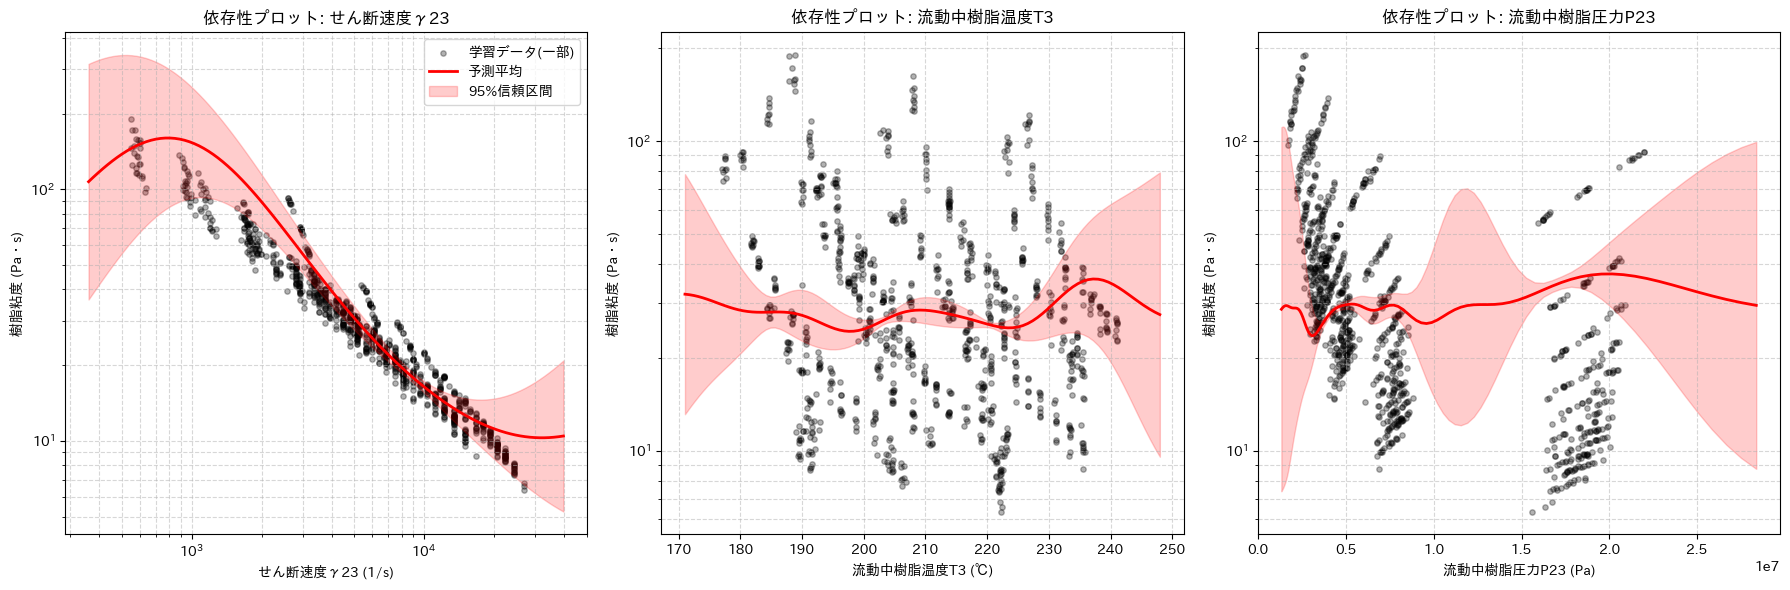

グラフを表示しました。


In [7]:
# セル6: 学習結果の可視化 (表示順序変更版：せん断速度を最初に)
if learning_completed:
    print("\n--- 学習結果の可視化を開始します ---")
    
    # --- 表示設定 ---
    # 表示したい順序でリストを定義します
    # data_idx: 学習データの列番号に対応 (0:温度, 1:圧力, 2:せん断速度)
    plot_configs = [
        {'name': 'せん断速度γ23',    'unit': '(1/s)', 'data_idx': 2},  # 1番目に表示 (元データの列2)
        {'name': '流動中樹脂温度T3',  'unit': '(℃)',   'data_idx': 0},  # 2番目に表示 (元データの列0)
        {'name': '流動中樹脂圧力P23',  'unit': '(Pa)',  'data_idx': 1}   # 3番目に表示 (元データの列1)
    ]
    
    # 3つのグラフを横に並べる
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    # 予測曲線を滑らかにするためのグリッド数
    n_grid = 100

    # enumerateでループ (iは画面上の表示位置 0, 1, 2)
    for i, config in enumerate(plot_configs):
        ax = axes[i]
        var_name = config['name']
        unit = config['unit']
        d_idx = config['data_idx'] # 実際のデータの列インデックスを取得
        
        # --- 1. 予測用データの作成 (X_new) ---
        # 対象変数の最小値～最大値の範囲を取得 (対応する列d_idxを使用)
        x_min, x_max = X_scaled[:, d_idx].min(), X_scaled[:, d_idx].max()
        padding = (x_max - x_min) * 0.1
        x_grid = np.linspace(x_min - padding, x_max + padding, n_grid)
        
        # 3次元の入力データを作成 (対象変数以外は0=平均値に固定)
        X_new_scaled = np.zeros((n_grid, 3))
        X_new_scaled[:, d_idx] = x_grid # 対象列にグリッドを入れる
        
        # --- 2. 予測の実行 ---
        # return_std=True で標準偏差も取得
        y_pred, y_std = gp_model.predict(X_new_scaled, return_std=True)
        
        # --- 3. データの逆変換と信頼区間の計算 ---
        # 平均値の逆変換: 中心化解除 -> exp
        y_pred_real_log = y_pred + y_mean
        visc_mean = np.exp(y_pred_real_log)
        
        # 95%信頼区間の計算 (平均 ± 1.96 * 標準偏差)
        y_lower_log = y_pred_real_log - 1.96 * y_std
        y_upper_log = y_pred_real_log + 1.96 * y_std
        visc_lower = np.exp(y_lower_log)
        visc_upper = np.exp(y_upper_log)
        
        # 横軸 (x): 標準化解除 -> exp (対応する列d_idxのスケールを使用)
        x_grid_unscaled = x_grid * scaler.scale_[d_idx] + scaler.mean_[d_idx]
        x_grid_real = np.exp(x_grid_unscaled)
        
        # 学習データ (散布図用 - ランダムサンプリング)
        # プロット用にも対応する列d_idxのデータを使う
        plot_indices = np.random.choice(len(X_raw), size=min(1000, len(X_raw)), replace=False)
        x_train_real = np.exp(X_raw[plot_indices, d_idx])
        y_train_real = np.exp(y_centered[plot_indices] + y_mean)
        
        # 温度の場合 (d_idxが0) の単位変換 (K -> ℃)
        if d_idx == 0: 
            x_grid_real = x_grid_real - 273.15
            x_train_real = x_train_real - 273.15
        
        # --- 4. グラフ描画 ---
        # 学習データのプロット
        ax.scatter(x_train_real, y_train_real, color='black', alpha=0.3, s=15, label='学習データ(一部)')
        
        # 予測平均のプロット
        ax.plot(x_grid_real, visc_mean, color='red', linewidth=2, label='予測平均')
        
        # 95%信頼区間のプロット
        ax.fill_between(x_grid_real, visc_lower, visc_upper, color='red', alpha=0.2, label='95%信頼区間')
        
        # タイトルと軸ラベル
        ax.set_title(f"依存性プロット: {var_name}")
        ax.set_xlabel(f"{var_name} {unit}")
        ax.set_ylabel("樹脂粘度 (Pa・s)")
        
        # --- 軸の対数設定 ---
        ax.set_yscale('log')
        
        # せん断速度 (d_idxが2) の場合のみX軸をログスケール
        if d_idx == 2: 
            ax.set_xscale('log')

        # グリッド
        ax.grid(True, which="both", linestyle='--', alpha=0.5)
        
        if i == 0: # 凡例は一番左のグラフにだけ表示
            ax.legend()

    plt.tight_layout()
    plt.show()
    print("グラフを表示しました。")


--- 学習結果の可視化（多変量解析用・色分け版）を開始します ---


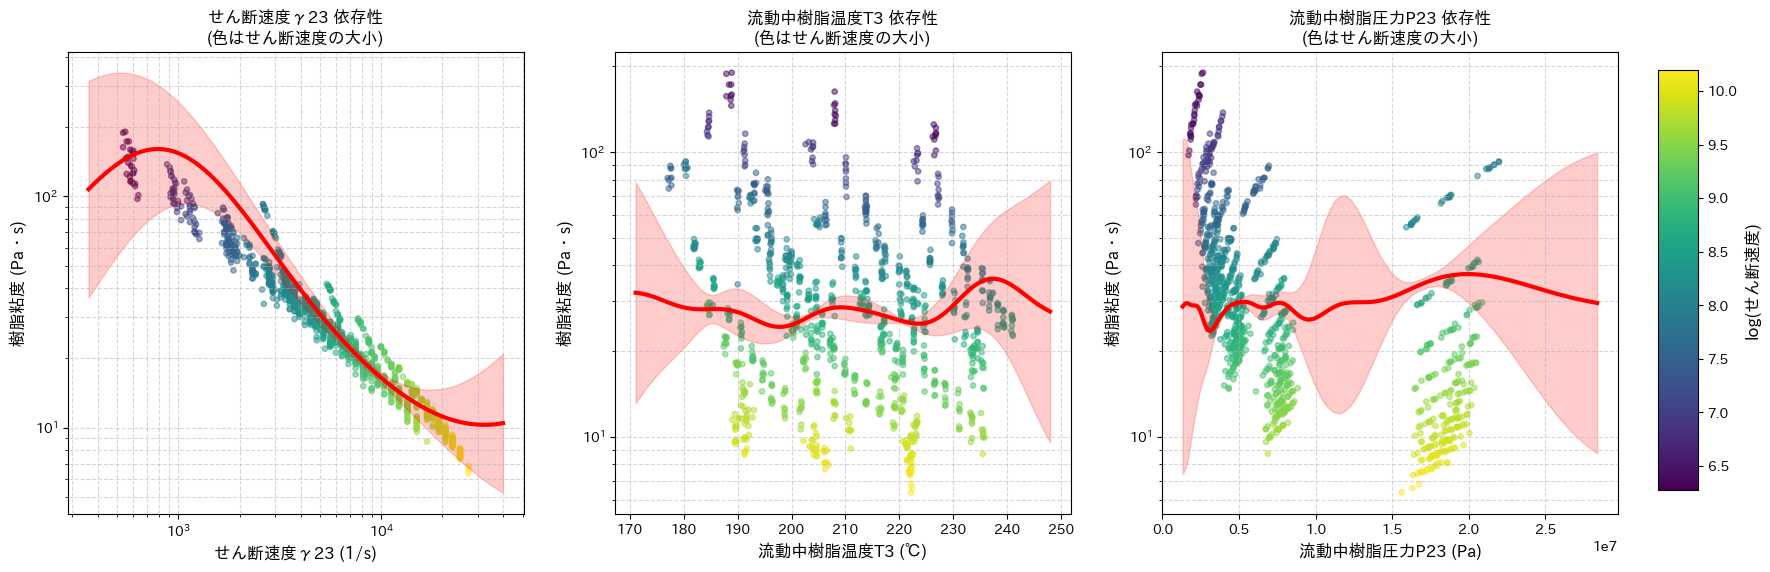

色付きグラフを表示しました。
温度や圧力のグラフで、色が綺麗なグラデーションになっていれば、モデルは正しく変数を分離できています。


In [8]:
# セル6: 学習結果の可視化 (せん断速度で色分けして、真の相関をあぶり出す版)
if learning_completed:
    print("\n--- 学習結果の可視化（多変量解析用・色分け版）を開始します ---")
    
    # 3つのグラフを横に並べる
    fig, axes = plt.subplots(1, 3, figsize=(20, 6)) # 少し幅を広げました
    
    # 予測曲線を滑らかにするためのグリッド数
    n_grid = 100

    # 色分けに使用する変数（最も支配的な「せん断速度」を使用）
    # 元データ列: 0=温度, 1=圧力, 2=せん断速度
    color_data = np.exp(X_raw[:, 2]) 
    color_label = "せん断速度 (1/s)"

    # 表示設定
    plot_configs = [
        {'name': 'せん断速度γ23',    'unit': '(1/s)', 'data_idx': 2},
        {'name': '流動中樹脂温度T3',  'unit': '(℃)',   'data_idx': 0},
        {'name': '流動中樹脂圧力P23',  'unit': '(Pa)',  'data_idx': 1}
    ]

    for i, config in enumerate(plot_configs):
        ax = axes[i]
        var_name = config['name']
        unit = config['unit']
        d_idx = config['data_idx']
        
        # --- 1. 予測用データの作成 ---
        x_min, x_max = X_scaled[:, d_idx].min(), X_scaled[:, d_idx].max()
        padding = (x_max - x_min) * 0.1
        x_grid = np.linspace(x_min - padding, x_max + padding, n_grid)
        
        X_new_scaled = np.zeros((n_grid, 3))
        X_new_scaled[:, d_idx] = x_grid
        
        # --- 2. 予測の実行 ---
        y_pred, y_std = gp_model.predict(X_new_scaled, return_std=True)
        
        # --- 3. 逆変換 ---
        y_pred_real_log = y_pred + y_mean
        visc_mean = np.exp(y_pred_real_log)
        
        y_lower_log = y_pred_real_log - 1.96 * y_std
        y_upper_log = y_pred_real_log + 1.96 * y_std
        visc_lower = np.exp(y_lower_log)
        visc_upper = np.exp(y_upper_log)
        
        x_grid_unscaled = x_grid * scaler.scale_[d_idx] + scaler.mean_[d_idx]
        x_grid_real = np.exp(x_grid_unscaled)
        
        # 学習データの準備（全データ使用）
        x_train_real = np.exp(X_raw[:, d_idx])
        y_train_real = np.exp(y_centered + y_mean)
        
        # 温度の単位変換
        if d_idx == 0: 
            x_grid_real = x_grid_real - 273.15
            x_train_real = x_train_real - 273.15
        
        # --- 4. グラフ描画（ここが変更点） ---
        # 散布図を「せん断速度」で色分けプロット (cmap='jet' or 'viridis')
        sc = ax.scatter(x_train_real, y_train_real, c=np.log(color_data), cmap='viridis', 
                        alpha=0.5, s=15, label='学習データ')
        
        # 予測線のプロット
        ax.plot(x_grid_real, visc_mean, color='red', linewidth=3, label='予測平均(他変数は平均値固定)')
        ax.fill_between(x_grid_real, visc_lower, visc_upper, color='red', alpha=0.2, label='95%信頼区間')
        
        ax.set_title(f"{var_name} 依存性\n(色はせん断速度の大小)", fontsize=12)
        ax.set_xlabel(f"{var_name} {unit}", fontsize=12)
        ax.set_ylabel("樹脂粘度 (Pa・s)", fontsize=12)
        
        ax.set_yscale('log')
        if d_idx == 2: ax.set_xscale('log')
        
        ax.grid(True, which="both", linestyle='--', alpha=0.5)

    # カラーバーの追加（右端）
    cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
    sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(vmin=np.log(color_data.min()), vmax=np.log(color_data.max())))
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cbar_ax)
    cbar.set_label('log(せん断速度)', fontsize=12)

    # レイアウト調整
    plt.subplots_adjust(right=0.9)
    plt.show()
    print("色付きグラフを表示しました。\n温度や圧力のグラフで、色が綺麗なグラデーションになっていれば、モデルは正しく変数を分離できています。")

Parity Plot（パリティプロット／実測値-予測値プロット）


--- 精度検証プロット (Parity Plot) の作成 ---


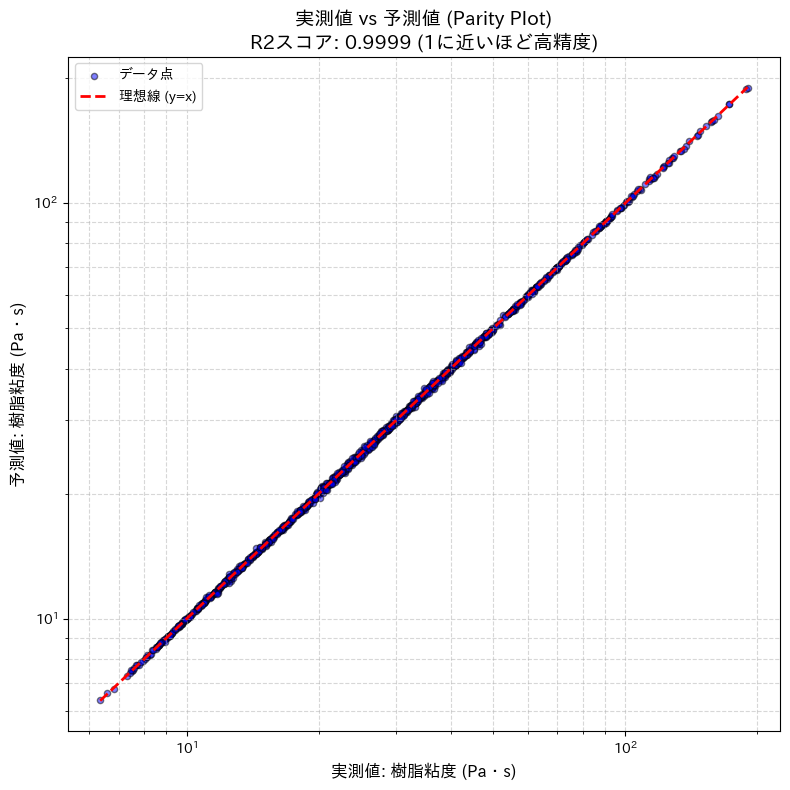

決定係数 (R2): 0.9999
RMSE (二乗平均平方根誤差): 0.2856
MAE (平均絶対誤差): 0.1925

【判定】: 非常に良好です。先ほどのグラフでデータが散らばっていたのは、単に多変数の影響が見えていただけです。


In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 学習完了フラグの確認
if 'gp_model' in locals() and 'X_scaled' in locals():
    print("\n--- 精度検証プロット (Parity Plot) の作成 ---")

    # 全データに対して予測を実行 (3つの変数をすべて考慮した予測)
    # ※メモリ節約のため、データが多い場合はランダムに3000点ほど抽出してもOK
    if len(X_scaled) > 3000:
        idx = np.random.choice(len(X_scaled), 3000, replace=False)
        X_test = X_scaled[idx]
        y_test_centered = y_centered[idx]
        y_test_real = np.exp(y_test_centered + y_mean) # 実測値 (Pa・s)
    else:
        X_test = X_scaled
        y_test_real = np.exp(y_centered + y_mean) # 実測値 (Pa・s)

    # 予測実行
    y_pred_centered, y_std = gp_model.predict(X_test, return_std=True)
    y_pred_real = np.exp(y_pred_centered + y_mean) # 予測値 (Pa・s)

    # 評価指標の計算
    r2 = r2_score(y_test_real, y_pred_real)
    rmse = np.sqrt(mean_squared_error(y_test_real, y_pred_real))
    mae = mean_absolute_error(y_test_real, y_pred_real)

    # --- グラフ描画 ---
    plt.figure(figsize=(8, 8))
    
    # 散布図 (実測値 vs 予測値)
    plt.scatter(y_test_real, y_pred_real, c='blue', alpha=0.5, edgecolors='k', s=20, label='データ点')
    
    # 45度線 (理想線)
    min_val = min(y_test_real.min(), y_pred_real.min())
    max_val = max(y_test_real.max(), y_pred_real.max())
    plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='理想線 (y=x)')

    # 対数軸設定 (粘度は桁が広いため対数が推奨)
    plt.xscale('log')
    plt.yscale('log')
    
    plt.title(f"実測値 vs 予測値 (Parity Plot)\nR2スコア: {r2:.4f} (1に近いほど高精度)", fontsize=14)
    plt.xlabel("実測値: 樹脂粘度 (Pa・s)", fontsize=12)
    plt.ylabel("予測値: 樹脂粘度 (Pa・s)", fontsize=12)
    plt.grid(True, which="both", linestyle='--', alpha=0.5)
    plt.legend()
    
    plt.tight_layout()
    plt.show()

    print(f"決定係数 (R2): {r2:.4f}")
    print(f"RMSE (二乗平均平方根誤差): {rmse:.4f}")
    print(f"MAE (平均絶対誤差): {mae:.4f}")
    
    if r2 > 0.9:
        print("\n【判定】: 非常に良好です。先ほどのグラフでデータが散らばっていたのは、単に多変数の影響が見えていただけです。")
    elif r2 > 0.7:
        print("\n【判定】: 良好です。CAE解析に十分使用可能です。")
    else:
        print("\n【判定】: 精度が低いです。ここで初めて「学習失敗」を疑う必要があります。")

else:
    print("モデルがまだ学習されていません。前のセルを実行してください。")


--- 【厳密な検証】ホールドアウト検証（学習データとテストデータの分割） ---
全データ数: 1076
学習用データ: 860 (モデル作成に使用)
テスト用データ: 216 (モデルには見せず、検証にのみ使用)
再学習中...完了


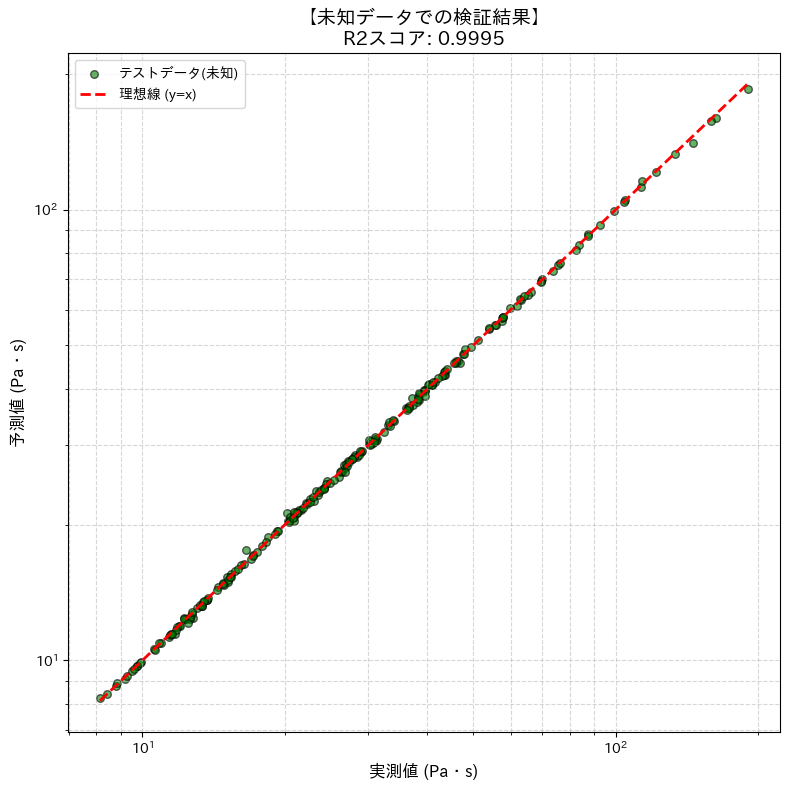


--- 判定結果 ---
R2スコア: 0.9995 -> 【合格】
モデルは未知のデータに対しても高い予測精度を持っています。
「丸暗記」ではなく、温度・圧力・せん断速度の「法則」を正しく学習しています。


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 実行制御
if 'X_scaled' in locals() and 'y_centered' in locals():
    print("\n--- 【厳密な検証】ホールドアウト検証（学習データとテストデータの分割） ---")

    # 1. データを「学習用(80%)」と「テスト用(20%)」に分割
    # random_stateを固定することで、毎回同じ分割になるようにしています
    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled, y_centered, test_size=0.2, random_state=42
    )
    
    print(f"全データ数: {len(X_scaled)}")
    print(f"学習用データ: {len(X_train)} (モデル作成に使用)")
    print(f"テスト用データ: {len(X_test)} (モデルには見せず、検証にのみ使用)")

    # 2. 学習用データ「だけ」を使ってモデルを再学習
    # (既存のモデル設定を引き継ぎます)
    kernel = C(1.0, (1e-3, 1e3)) * RBF(length_scale=[1.0, 1.0, 1.0], length_scale_bounds=(1e-2, 1e2)) + \
             WhiteKernel(noise_level=0.1, noise_level_bounds=(1e-5, 1e1))
    
    gp_model_valid = GaussianProcessRegressor(
        kernel=kernel, 
        n_restarts_optimizer=10, 
        random_state=42
    )
    
    # ダウンサンプリング処理 (学習データが多すぎる場合)
    if len(X_train) > 2000:
        idx_train = np.random.choice(len(X_train), 2000, replace=False)
        X_train_fit = X_train[idx_train]
        y_train_fit = y_train[idx_train]
    else:
        X_train_fit = X_train
        y_train_fit = y_train

    print("再学習中...", end="")
    gp_model_valid.fit(X_train_fit, y_train_fit)
    print("完了")

    # 3. テスト用データに対して予測を実行 (カンニングなしのテスト)
    y_pred_test_centered, y_std_test = gp_model_valid.predict(X_test, return_std=True)

    # 4. 単位を元に戻す (対数 -> 実数)
    y_test_real = np.exp(y_test + y_mean)       # 実測値（正解）
    y_pred_test_real = np.exp(y_pred_test_centered + y_mean) # 予測値（モデルの回答）

    # 5. 評価指標の計算
    r2 = r2_score(y_test_real, y_pred_test_real)
    rmse = np.sqrt(mean_squared_error(y_test_real, y_pred_test_real))

    # --- グラフ描画 ---
    plt.figure(figsize=(8, 8))
    
    # 散布図 (テストデータのみプロット)
    plt.scatter(y_test_real, y_pred_test_real, c='green', alpha=0.6, edgecolors='k', s=30, label='テストデータ(未知)')
    
    # 理想線
    min_val = min(y_test_real.min(), y_pred_test_real.min())
    max_val = max(y_test_real.max(), y_pred_test_real.max())
    plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='理想線 (y=x)')

    plt.xscale('log')
    plt.yscale('log')
    plt.title(f"【未知データでの検証結果】\nR2スコア: {r2:.4f}", fontsize=14)
    plt.xlabel("実測値 (Pa・s)", fontsize=12)
    plt.ylabel("予測値 (Pa・s)", fontsize=12)
    plt.grid(True, which="both", linestyle='--', alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print("\n--- 判定結果 ---")
    if r2 > 0.9:
        print(f"R2スコア: {r2:.4f} -> 【合格】")
        print("モデルは未知のデータに対しても高い予測精度を持っています。")
        print("「丸暗記」ではなく、温度・圧力・せん断速度の「法則」を正しく学習しています。")
    elif r2 > 0.7:
        print(f"R2スコア: {r2:.4f} -> 【条件付き合格】")
        print("概ね傾向は捉えていますが、一部予測が外れる領域があります。")
    else:
        print(f"R2スコア: {r2:.4f} -> 【不合格】")
        print("学習データでは合っていましたが、未知のデータでは精度が落ちています（過学習の疑い）。")

else:
    print("データが読み込まれていません。")